In [1]:
import os, glob
import numpy as np
import torch
from torch.utils.data import IterableDataset, DataLoader

class NPZIterable(IterableDataset):
    def __init__(self, npz_files, use_weights=True, keep_only_valid=True, min_wsum=50.0):
        self.npz_files = list(npz_files)
        self.use_weights = use_weights
        self.keep_only_valid = keep_only_valid
        self.min_wsum = float(min_wsum)

    def __iter__(self):
        for f in self.npz_files:
            d = np.load(f, allow_pickle=True)

            X = d["X"]
            W = d["W"] if (self.use_weights and "W" in d.files) else None
            spectype = d["SPECTYPE"]
            targetid = d["TARGETID"] 

            if X.ndim == 3:
                X = X[:, 0, :]
            if W is not None and W.ndim == 3:
                W = W[:, 0, :]

            keep = np.ones(X.shape[0], dtype=bool)

            if self.keep_only_valid:
                if "keep_train" in d.files:
                    keep &= d["keep_train"].astype(bool)

                if W is not None:
                    keep &= (W.sum(axis=1) > self.min_wsum)

                keep &= np.isfinite(X).all(axis=1)

            for i in range(X.shape[0]):
                if not keep[i]:
                    continue

                x = torch.from_numpy(X[i]).float()
                s = spectype[i]
                tid = targetid[i]   

                if W is None:
                    yield x, None, s, tid
                else:
                    w = torch.from_numpy(W[i]).float()
                    yield x, w, s, tid

def collate(batch):
    xs, ws, ss, tids = zip(*batch)
    X = torch.stack(xs, dim=0)
    W = None if ws[0] is None else torch.stack(ws, dim=0)
    S = np.array(ss)
    TID = np.array(tids)
    return X, W, S, TID

In [2]:
clean_dir = "/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/galaxy_spectra_preprocess"

npz_files = sorted(glob.glob(os.path.join(clean_dir, "*_prep_1000.npz")))

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 512
loader = DataLoader(
    NPZIterable(npz_files, use_weights=True),
    batch_size=batch_size,
    num_workers=2,
    pin_memory=(device=="cuda"),
    collate_fn=collate
)


In [ ]:
from sklearn.decomposition import IncrementalPCA
import numpy as np

n_components = 16

pca = IncrementalPCA(
    n_components=n_components,
    batch_size=4096,
)

buffer = []

for X, W, labels, targetids in loader:
    X = X.cpu().numpy().astype(np.float32)
    labels = np.asarray(labels)

    normal_mask = np.isin(labels, ["GALAXY", "QSO"])
    X_normal = X[normal_mask]

    if len(X_normal) > 0:
        buffer.append(X_normal)

    n_buffered = sum(len(x) for x in buffer)

    if n_buffered >= 4096:
        X_fit = np.concatenate(buffer, axis=0)
        pca.partial_fit(X_fit)
        buffer = []

if buffer:
    X_fit = np.concatenate(buffer, axis=0)

    if len(X_fit) >= n_components:
        pca.partial_fit(X_fit)

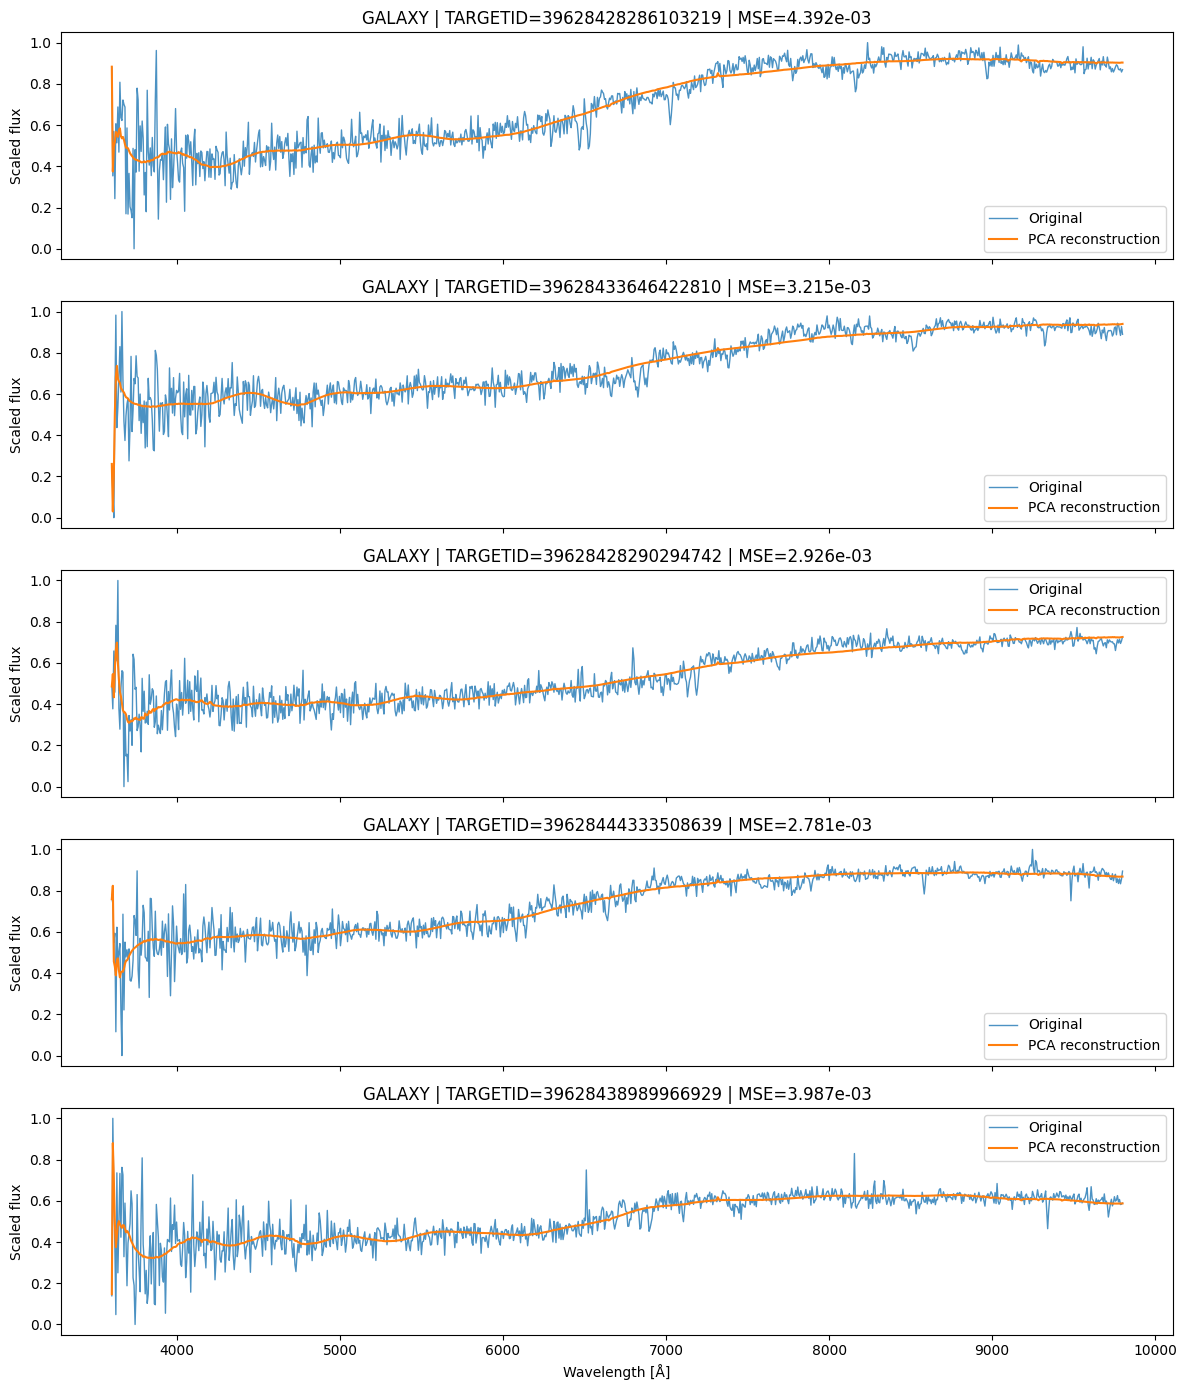

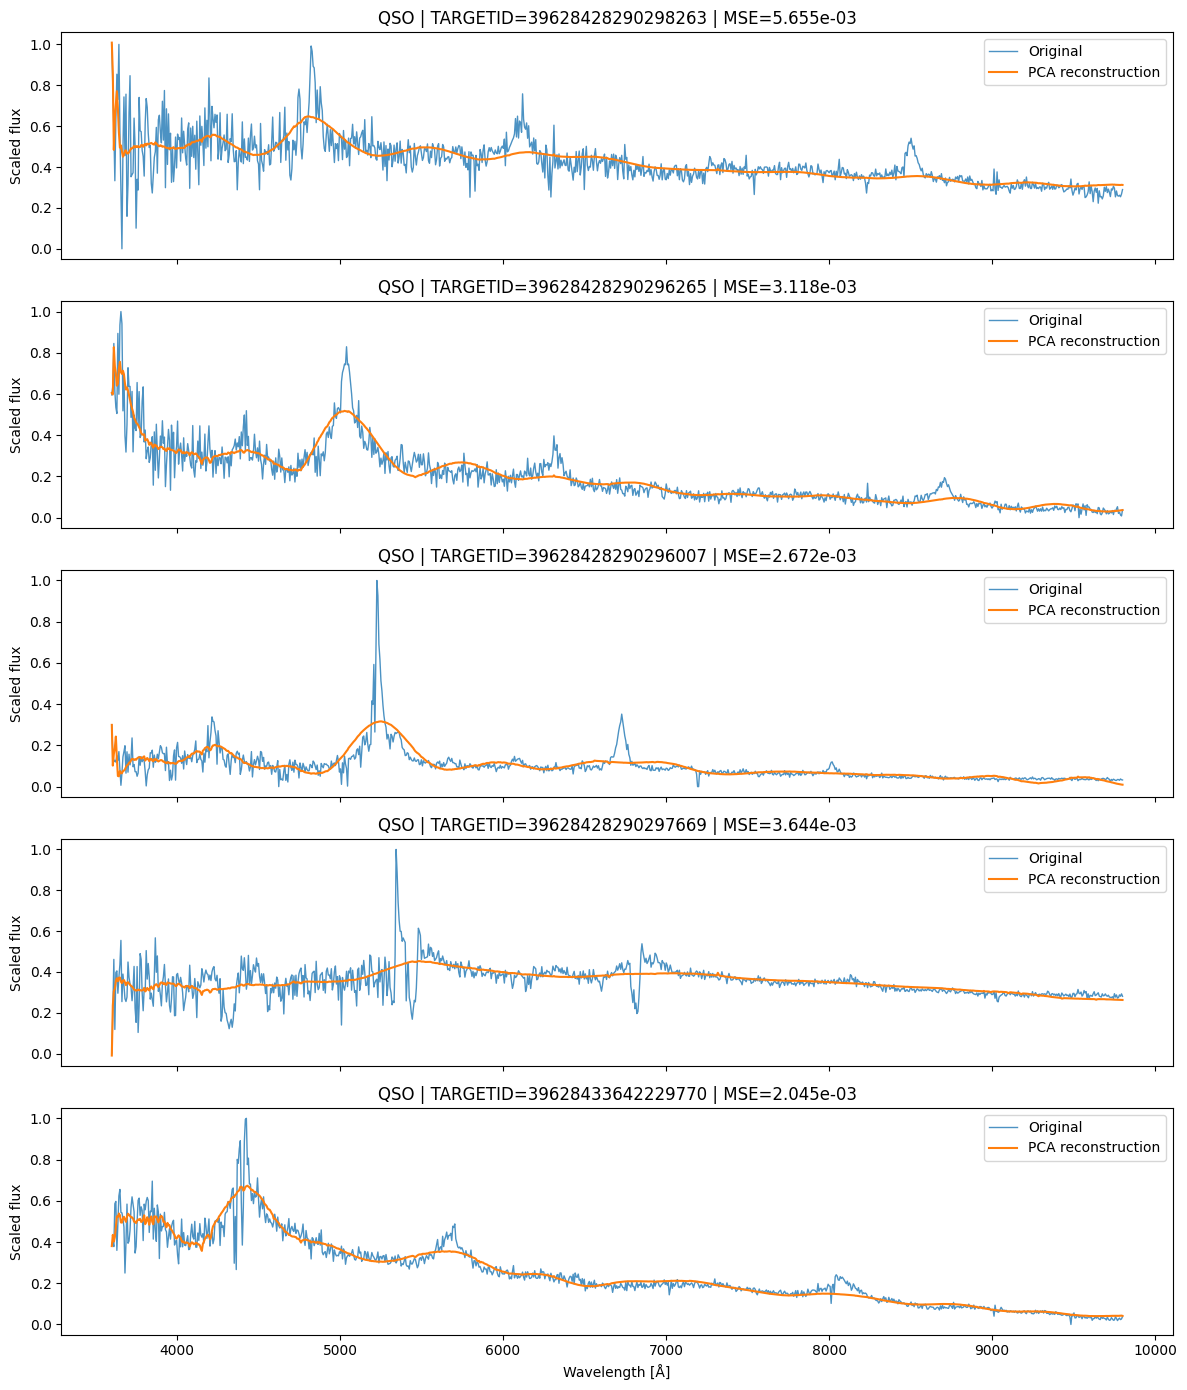

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Get one batch
X, W, labels, targetids = next(iter(loader))

X = X.cpu().numpy().astype(np.float32)
labels = np.asarray(labels)
targetids = np.asarray(targetids)

# PCA reconstruction
Z = pca.transform(X)
X_rec = pca.inverse_transform(Z)

# Reconstruction error for each spectrum
mse = np.mean((X - X_rec)**2, axis=1)

# Use your actual wave_grid here if you already have it
wave_grid = np.linspace(3600, 9800, X.shape[1])


def plot_reconstructions(
    X,
    X_rec,
    labels,
    targetids,
    mse,
    wave_grid,
    spectype,
    n=5,
):
    idx = np.where(labels == spectype)[0][:n]

    fig, axes = plt.subplots(
        len(idx),
        1,
        figsize=(12, 2.8 * len(idx)),
        sharex=True,
    )

    if len(idx) == 1:
        axes = [axes]

    for ax, i in zip(axes, idx):

        ax.plot(
            wave_grid,
            X[i],
            lw=1,
            alpha=0.8,
            label="Original",
        )

        ax.plot(
            wave_grid,
            X_rec[i],
            lw=1.5,
            label="PCA reconstruction",
        )

        ax.set_title(
            f"{spectype} | TARGETID={targetids[i]} | "
            f"MSE={mse[i]:.3e}"
        )

        ax.set_ylabel("Scaled flux")
        ax.legend()

    axes[-1].set_xlabel("Wavelength [Å]")

    plt.tight_layout()
    plt.show()


plot_reconstructions(
    X,
    X_rec,
    labels,
    targetids,
    mse,
    wave_grid,
    spectype="GALAXY",
    n=5,
)

plot_reconstructions(
    X,
    X_rec,
    labels,
    targetids,
    mse,
    wave_grid,
    spectype="QSO",
    n=5,
)

In [1]:
import joblib

joblib.dump(pca, "pca_galaxy_qso_16d.joblib")

NameError: name 'pca' is not defined

In [4]:
import joblib

pca = joblib.load('pca_galaxy_qso_16d.joblib')

In [10]:
from tqdm import tqdm
import numpy as np
import torch

sample_fraction = 0.20
seed = 42

rng = np.random.default_rng(seed)

torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


selected_targetids = []
selected_labels = []
selected_wmse = []


n_total = 0
n_selected = 0

In [12]:
pca_mean = torch.as_tensor(
    pca.mean_,
    dtype=torch.float32,
    device=device
)

pca_components = torch.as_tensor(
    pca.components_,
    dtype=torch.float32,
    device=device
)

In [16]:
#recon error
from tqdm import tqdm

n_total_pca = 0
n_selected_pca = 0

rng_pca = np.random.default_rng(42)

for batch_i, (X, W, labels, targetids) in enumerate(
    tqdm(loader, desc="PCA reconstruction error")
):

    labels = np.asarray(labels).astype(str)
    targetids = np.asarray(targetids).reshape(-1)

    batch_size = len(labels)
    n_total_pca += batch_size

    keep = rng_pca.random(batch_size) < sample_fraction

    if not np.any(keep):
        continue

    idx = np.flatnonzero(keep)

    # PCA operates on numpy arrays
    x = X[idx].to(
        device,
        dtype=torch.float32,
        non_blocking=True,
    )
    
    ivar = W[idx].to(
        device,
        dtype=torch.float32,
        non_blocking=True,
    )

    labels_sel = labels[idx]
    targetids_sel = targetids[idx]

    z_pca = (x - pca_mean) @ pca_components.T
    
    xhat_pca = (
        z_pca @ pca_components
        + pca_mean
    )

    assert x.shape == xhat_pca.shape, (
        f"x shape = {x.shape}, "
        f"xhat_pca shape = {xhat_pca.shape}"
    )

    w = torch.sqrt(
        ivar.clamp_min(0.0)
    )
    
    pixel_loss_pca = (
        0.5
        * w
        * (x - xhat_pca).pow(2)
    )
    
    recon_spec = pixel_loss_pca.sum(dim=1)


    assert recon_spec.ndim == 1
    assert recon_spec.shape[0] == len(idx)

    # save
    selected_wmse_pca.append(
        recon_spec.detach().cpu().numpy().astype(np.float32)
    )

    selected_targetids_pca.append(
        np.asarray(targetids_sel).reshape(-1)
    )

    selected_labels_pca.append(
        np.asarray(labels_sel).reshape(-1)
    )

    n_selected_pca += len(idx)

PCA reconstruction error: 125it [00:14, 11.29it/s]<function _MultiProcessingDataLoaderIter.__del__ at 0x7f1e8d35e020>
Traceback (most recent call last):
  File "/global/common/software/nersc9/pytorch/2.6.0/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1618, in __del__
    self._shutdown_workers()
  File "/global/common/software/nersc9/pytorch/2.6.0/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1601, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/global/common/software/nersc9/pytorch/2.6.0/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
PCA reconstruction error: 149it [00:18,  7.81it/s]Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f1e8d35e020>
Traceback (most recent call last):
PCA reconstruction error: 151it [0

In [17]:
selected_targetids_pca = np.concatenate(
    selected_targetids_pca
)

selected_labels_pca = np.concatenate(
    selected_labels_pca
)

selected_wmse_pca = np.concatenate(
    selected_wmse_pca
).astype(np.float32)

In [19]:
gal_mask = selected_labels_pca == "GALAXY"
qso_mask = selected_labels_pca == "QSO"

print("GALAXY:", gal_mask.sum())
print("QSO:   ", qso_mask.sum())
print("Other: ", (~(gal_mask | qso_mask)).sum())

GALAXY: 3696674
QSO:    274744
Other:  88


In [21]:
gal_targetids = selected_targetids_pca[gal_mask]
gal_wmse = selected_wmse_pca[gal_mask]

qso_targetids = selected_targetids_pca[qso_mask]
qso_wmse = selected_wmse_pca[qso_mask]

In [22]:
import numpy as np

np.savez_compressed(
    "/global/cfs/cdirs/desi/users/zixinq/vae_dr2/results/pca_recon_error.npz",
    gal_targetids=gal_targetids,
    gal_wmse=gal_wmse,
    qso_targetids=qso_targetids,
    qso_wmse=qso_wmse,
)

In [23]:
import numpy as np

data = np.load("/global/cfs/cdirs/desi/users/zixinq/vae_dr2/results/vae_recon_error.npz")

vae_gal = data["gal_wmse"]
vae_qso = data["qso_wmse"]

print("GALAXY:", len(vae_gal))
print("QSO:", len(vae_qso))

GALAXY: 3581007
QSO: 249594


In [24]:
import numpy as np

data = np.load("/global/cfs/cdirs/desi/users/zixinq/vae_dr2/results/pca_recon_error.npz")

pca_gal = data["gal_wmse"]
pca_qso = data["qso_wmse"]

print("GALAXY:", len(vae_gal))
print("QSO:", len(vae_qso))

GALAXY: 3581007
QSO: 249594


In [26]:
def summarize(x):
    x = np.asarray(x)

    return {
        "mean": np.mean(x),
        "median": np.median(x),
        "p90": np.percentile(x, 90),
        "p95": np.percentile(x, 95),
        "p99": np.percentile(x, 99),
        "p99.9": np.percentile(x, 99.9),
    }


print("VAE GALAXY")
print(summarize(vae_gal))

print("\nPCA GALAXY")
print(summarize(pca_gal))

print("\nVAE QSO")
print(summarize(vae_qso))

print("\nPCA QSO")
print(summarize(pca_qso))

VAE GALAXY
{'mean': np.float32(2.4517145), 'median': np.float32(1.1756454), 'p90': np.float32(2.397987), 'p95': np.float32(4.150894), 'p99': np.float32(16.08464), 'p99.9': np.float32(114.30121)}

PCA GALAXY
{'mean': np.float32(39.765415), 'median': np.float32(30.589087), 'p90': np.float32(60.845413), 'p95': np.float32(87.72268), 'p99': np.float32(197.06792), 'p99.9': np.float32(568.02466)}

VAE QSO
{'mean': np.float32(3.5887885), 'median': np.float32(1.3878798), 'p90': np.float32(4.9541116), 'p95': np.float32(9.085603), 'p99': np.float32(32.714363), 'p99.9': np.float32(155.80595)}

PCA QSO
{'mean': np.float32(51.01771), 'median': np.float32(34.28844), 'p90': np.float32(90.23919), 'p95': np.float32(131.60031), 'p99': np.float32(293.72278), 'p99.9': np.float32(770.4375)}


In [27]:
import pandas as pd

summary = pd.DataFrame({
    ("GALAXY", "VAE"): summarize(vae_gal),
    ("GALAXY", "PCA"): summarize(pca_gal),
    ("QSO", "VAE"): summarize(vae_qso),
    ("QSO", "PCA"): summarize(pca_qso),
}).T

summary

mean     median        p90         p95         p99  \
GALAXY VAE   2.451715   1.175645   2.397987    4.150894   16.084641   
       PCA  39.765415  30.589087  60.845413   87.722679  197.067917   
QSO    VAE   3.588789   1.387880   4.954112    9.085603   32.714363   
       PCA  51.017712  34.288441  90.239189  131.600311  293.722778   

                 p99.9  
GALAXY VAE  114.301208  
       PCA  568.024658  
QSO    VAE  155.805954  
       PCA  770.437500

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

y = (labels_sample == "QSO").astype(int)

train_idx, test_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.25,
    random_state=42,
    stratify=y
)



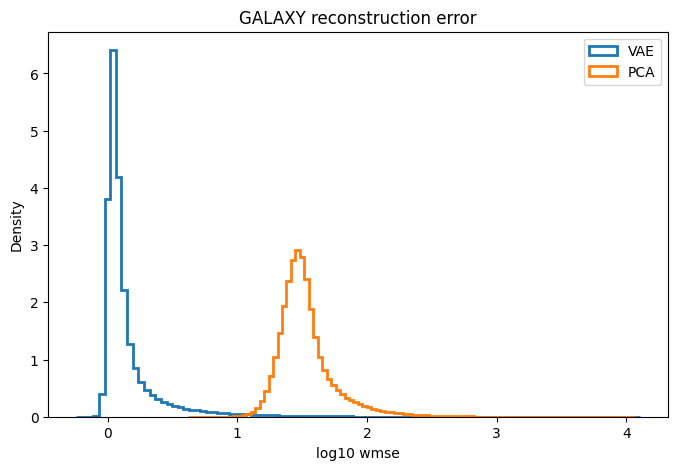

In [31]:
import matplotlib.pyplot as plt

eps = 1e-12

plt.figure(figsize=(8, 5))

plt.hist(
    np.log10(vae_gal + eps),
    bins=100,
    density=True,
    histtype="step",
    linewidth=2,
    label="VAE"
)

plt.hist(
    np.log10(pca_gal + eps),
    bins=100,
    density=True,
    histtype="step",
    linewidth=2,
    label="PCA"
)

plt.xlabel("log10 wmse")
plt.ylabel("Density")
plt.title("GALAXY reconstruction error")
plt.legend()
plt.show()

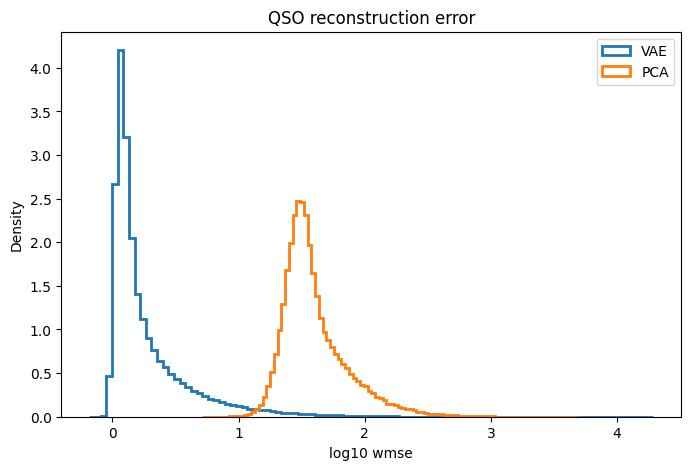

In [33]:
plt.figure(figsize=(8, 5))

plt.hist(
    np.log10(vae_qso + eps),
    bins=100,
    density=True,
    histtype="step",
    linewidth=2,
    label="VAE"
)

plt.hist(
    np.log10(pca_qso + eps),
    bins=100,
    density=True,
    histtype="step",
    linewidth=2,
    label="PCA"
)

plt.xlabel("log10 wmse")
plt.ylabel("Density")
plt.title("QSO reconstruction error")
plt.legend()
plt.show()

In [4]:
import numpy as np
import torch
from tqdm import tqdm


class WeightedPCA:
    def __init__(
        self,
        n_components=16,
        device="cuda",
        ridge=1e-5,
    ):
        self.n_components = n_components
        self.device = device
        self.ridge = ridge

        self.mean_ = None
        self.components_ = None


    def get_weight(self, ivar):
        # w = sqrt(ivar)
        return torch.sqrt(
            ivar.clamp_min(0.0)
        )


    @torch.no_grad()
    def fit_mean(self, loader):
        sum_wx = None
        sum_w = None

        for X, W, labels, targetids in tqdm(
            loader,
            desc="Weighted mean"
        ):

            x = X.to(
                self.device,
                dtype=torch.float64,
                non_blocking=True
            )

            ivar = W.to(
                self.device,
                dtype=torch.float64,
                non_blocking=True
            )

            w = self.get_weight(ivar)

            if sum_wx is None:
                n_wave = x.shape[1]

                sum_wx = torch.zeros(
                    n_wave,
                    dtype=torch.float64,
                    device=self.device
                )

                sum_w = torch.zeros_like(sum_wx)

            sum_wx += (w * x).sum(dim=0)
            sum_w += w.sum(dim=0)

        self.mean_ = (
            sum_wx /
            sum_w.clamp_min(1e-12)
        ).float()

        return self.mean_


    @torch.no_grad()
    def initialize_components(self, n_wave, seed=42):

        torch.manual_seed(seed)

        A = torch.randn(
            n_wave,
            self.n_components,
            device=self.device
        )

        Q, _ = torch.linalg.qr(A)

        self.components_ = (
            Q[:, :self.n_components]
            .T
            .contiguous()
        )


    @torch.no_grad()
    def solve_latent(self, x, ivar, components=None):
        """
        Solve weighted least squares for latent coordinates z.

        xhat = mean + z @ components
        """

        if components is None:
            components = self.components_

        w = self.get_weight(ivar)

        y = x - self.mean_[None, :]

        C = components

        # A_i = C diag(w_i) C^T
        A = torch.einsum(
            "bd,kd,ld->bkl",
            w,
            C,
            C
        )

        eye = torch.eye(
            self.n_components,
            device=x.device,
            dtype=x.dtype
        )

        A = (
            A
            + self.ridge * eye[None, :, :]
        )

        # b_i = C diag(w_i) y_i
        b = torch.einsum(
            "bd,bd,kd->bk",
            w,
            y,
            C
        )

        z = torch.linalg.solve(
            A,
            b.unsqueeze(-1)
        ).squeeze(-1)

        return z


    def fit(
        self,
        loader,
        n_epochs=5,
        lr=1e-3,
    ):


        if self.mean_ is None:
            self.fit_mean(loader)


        if self.components_ is None:

            for X, W, labels, targetids in loader:
                self.initialize_components(
                    X.shape[1]
                )
                break

        C = torch.nn.Parameter(
            self.components_.clone()
        )

        optimizer = torch.optim.Adam(
            [C],
            lr=lr
        )

        for epoch in range(n_epochs):

            total_loss = 0.0
            total_weight = 0.0

            pbar = tqdm(
                loader,
                desc=f"WPCA epoch {epoch+1}/{n_epochs}"
            )

            for X, W, labels, targetids in pbar:

                x = X.to(
                    self.device,
                    dtype=torch.float32,
                    non_blocking=True
                )

                ivar = W.to(
                    self.device,
                    dtype=torch.float32,
                    non_blocking=True
                )

                w = self.get_weight(ivar)

                # -----------------------
                # solve z
                # -----------------------

                with torch.no_grad():

                    z = self.solve_latent(
                        x,
                        ivar,
                        components=C
                    )

                # -----------------------
                # reconstruct
                # -----------------------

                xhat = (
                    self.mean_[None, :]
                    + z @ C
                )

                residual = x - xhat

                # SAME reconstruction objective
                # as your VAE
                loss_sum = torch.sum(
                    0.5
                    * w
                    * residual.pow(2)
                )

                denom = w.sum().clamp_min(1e-12)

                loss = loss_sum / denom

                # -----------------------
                # update components
                # -----------------------

                optimizer.zero_grad()

                loss.backward()

                optimizer.step()

                total_loss += loss_sum.item()
                total_weight += denom.item()

                pbar.set_postfix(
                    loss=total_loss /
                    max(total_weight, 1e-12)
                )

            # Keep components orthonormal
            with torch.no_grad():

                Q, _ = torch.linalg.qr(C.T)

                C.copy_(
                    Q[:, :self.n_components].T
                )

        self.components_ = C.detach()

        return self


    @torch.no_grad()
    def transform(self, x, ivar):

        x = x.to(
            self.device,
            dtype=torch.float32
        )

        ivar = ivar.to(
            self.device,
            dtype=torch.float32
        )

        return self.solve_latent(
            x,
            ivar
        )


    @torch.no_grad()
    def reconstruct(self, x, ivar):

        x = x.to(
            self.device,
            dtype=torch.float32
        )

        ivar = ivar.to(
            self.device,
            dtype=torch.float32
        )

        z = self.solve_latent(
            x,
            ivar
        )

        xhat = (
            self.mean_[None, :]
            + z @ self.components_
        )

        return xhat, z

In [5]:
wpca = WeightedPCA(
    n_components=16,
    device=device,
    ridge=1e-5,
)

wpca.fit(
    loader,
    n_epochs=10,
    lr=1e-3,
)

Weighted mean: 40it [00:06,  6.25it/s]


KeyboardInterrupt: 

In [ ]:
torch.save(
    {
        "n_components": wpca.n_components,
        "ridge": wpca.ridge,

        "mean": wpca.mean_.cpu(),
        "components": wpca.components_.cpu(),
    },
    "weighted_pca_16qq.pt"
)

In [7]:
checkpoint = torch.load(
    "weighted_pca_16qq.pt",
    map_location=device
)

wpca = WeightedPCA(
    n_components=checkpoint["n_components"],
    device=device,
    ridge=checkpoint["ridge"],
)

wpca.mean_ = checkpoint["mean"].to(device)
wpca.components_ = checkpoint["components"].to(device)

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# Get one batch
X, W, labels, targetids = next(iter(loader))

x = X.to(
    device,
    dtype=torch.float32
)

ivar = W.to(
    device,
    dtype=torch.float32
)

# Weighted PCA reconstruction
with torch.inference_mode():
    xhat, z = wpca.reconstruct(x, ivar)

# Move to CPU
x_np = x.cpu().numpy()
xhat_np = xhat.cpu().numpy()
ivar_np = ivar.cpu().numpy()

labels = np.asarray(labels)
targetids = np.asarray(targetids)

with np.load(npz_files[0], allow_pickle=True) as d:
    wave = d["wave_grid"]

print(wave.shape)

(1000,)


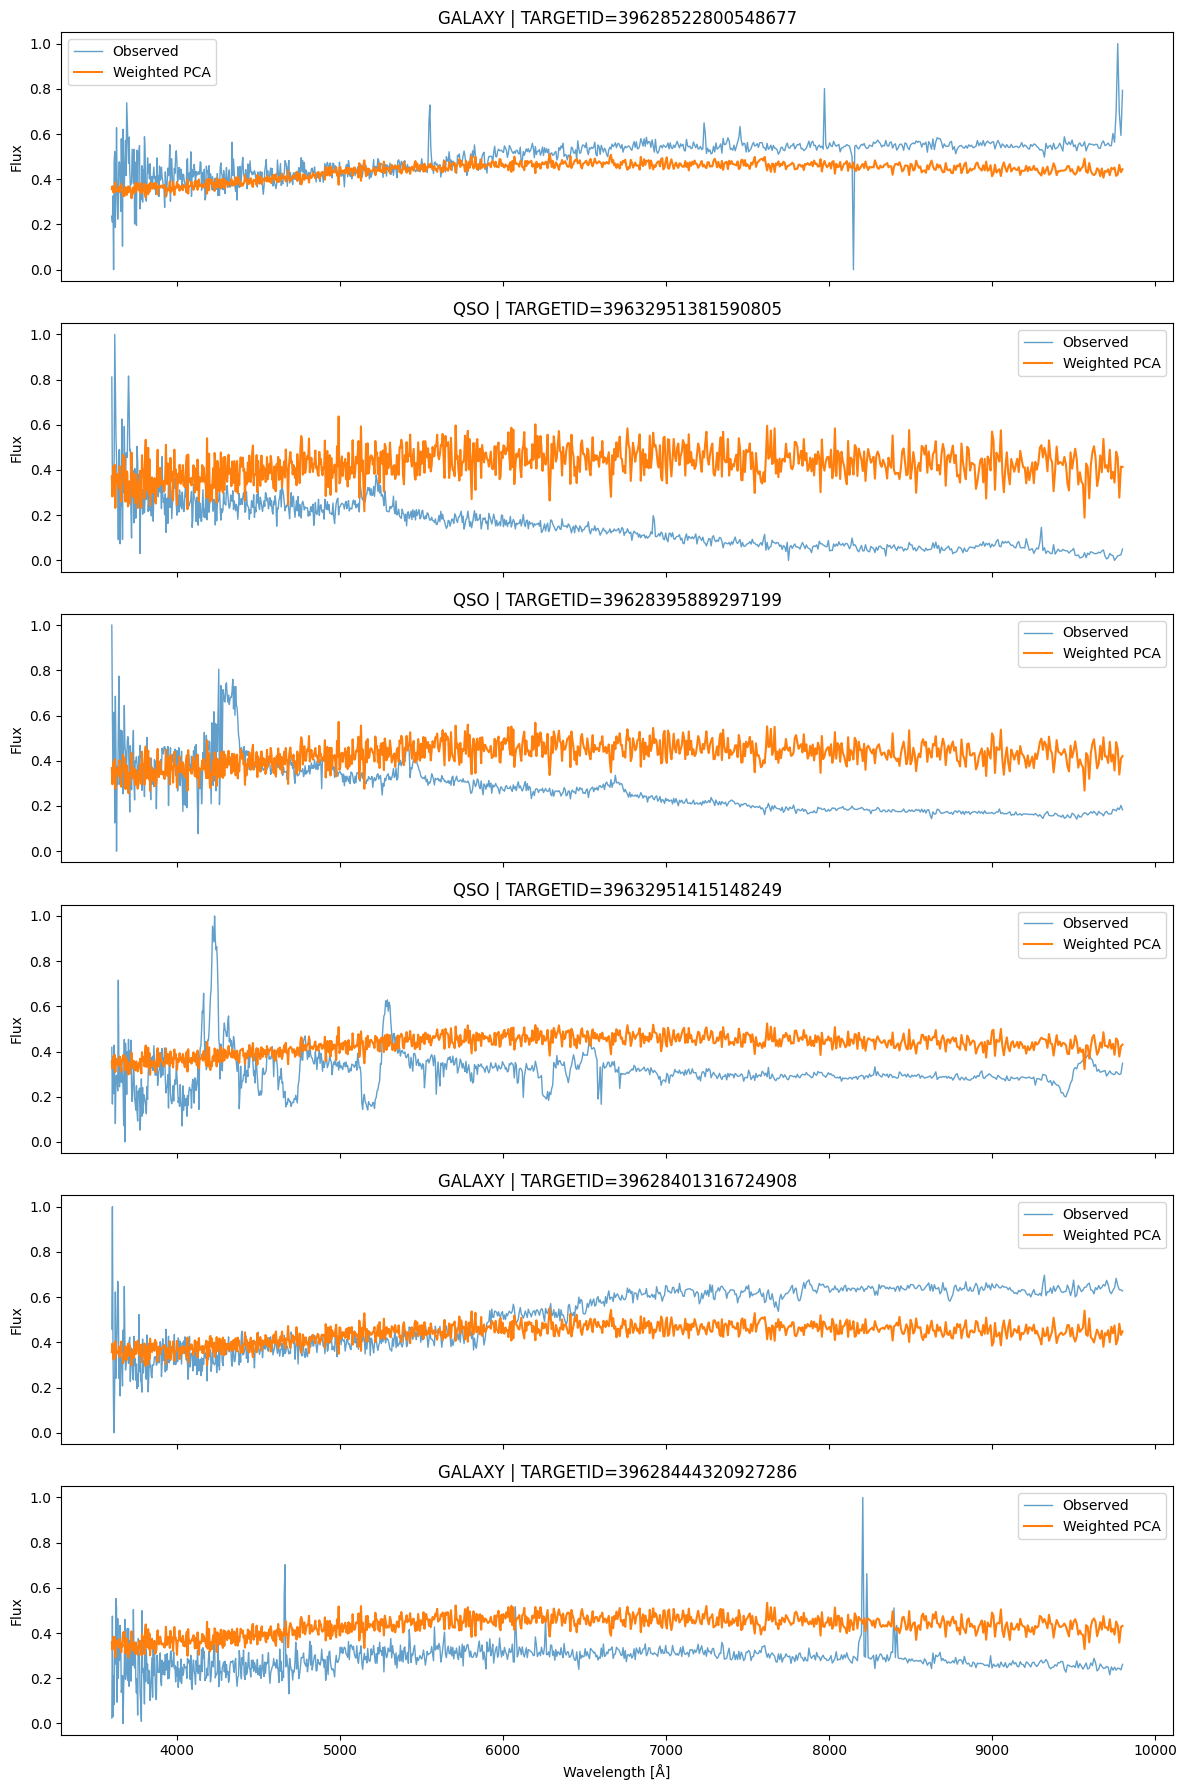

In [9]:
rng = np.random.default_rng(42)

n_plot = 6
idxs = rng.choice(
    len(x_np),
    size=n_plot,
    replace=False
)

fig, axes = plt.subplots(
    n_plot,
    1,
    figsize=(12, 3 * n_plot),
    sharex=True
)

for ax, i in zip(axes, idxs):

    ax.plot(
        wave,
        x_np[i],
        lw=1,
        alpha=0.7,
        label="Observed"
    )

    ax.plot(
        wave,
        xhat_np[i],
        lw=1.5,
        label="Weighted PCA"
    )

    ax.set_title(
        f"{labels[i]} | TARGETID={targetids[i]}"
    )

    ax.set_ylabel("Flux")
    ax.legend()

axes[-1].set_xlabel("Wavelength [Å]")

plt.tight_layout()
plt.show()

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------
# 1. Collect GALAXY + QSO PCA representations
# -----------------------------------------

latent_list = []
label_list = []
tid_list = []

for X, W, labels, targetids in loader:

    X = X.cpu().numpy().astype(np.float32)
    labels = np.asarray(labels)
    targetids = np.asarray(targetids)

    # Project into fitted PCA space
    Z = pca.transform(X)

    latent_list.append(Z)
    label_list.append(labels)
    tid_list.append(targetids)


Z_normal = np.concatenate(latent_list, axis=0)
labels_normal = np.concatenate(label_list, axis=0)
targetids_normal = np.concatenate(tid_list, axis=0)

print(Z_normal.shape)
print(np.unique(labels_normal, return_counts=True))

KeyboardInterrupt: 

In [ ]:
rng = np.random.default_rng(42)

n_plot = 20000

gal_idx = np.where(labels_normal == "GALAXY")[0]
qso_idx = np.where(labels_normal == "QSO")[0]

gal_idx = rng.choice(
    gal_idx,
    size=min(n_plot, len(gal_idx)),
    replace=False
)

qso_idx = rng.choice(
    qso_idx,
    size=min(n_plot, len(qso_idx)),
    replace=False
)

In [5]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

class TransientNPZDataset(Dataset):
    def __init__(self, npz_path, use_weights=True):
        d = np.load(npz_path, allow_pickle=True)
        self.X = d["X"].astype(np.float32, copy=False)
        self.W = d["W"].astype(np.float32, copy=False) if ("W" in d.files and use_weights) else None
        self.Z = d["Z"].astype(np.float32, copy=False) if "Z" in d.files else None
        self.TYPE = d["TYPE"] if "TYPE" in d.files else None
        self.TARGETID = d["TARGETID"].astype(np.int64, copy=False) if "TARGETID" in d.files else None

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, i):
        x = self.X[i]
        if self.W is None:
            w = np.ones_like(x, dtype=np.float32)
        else:
            w = self.W[i]

        tid = -1 if self.TARGETID is None else self.TARGETID[i]

        # return X, W, TARGETID
        return x, w, tid

def collate_XW(batch):
    X, W, TID = zip(*batch)
    X = torch.from_numpy(np.stack(X, axis=0))              # (B, L)
    W = torch.from_numpy(np.stack(W, axis=0))              # (B, L)
    TID = np.asarray(TID, dtype=np.int64)                  # (B,)
    return X, W, TID

trans_npz = "/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/transients_preprocessed_all.npz"

trans_loader = DataLoader(
    TransientNPZDataset(trans_npz, use_weights=True),
    batch_size=32,
    num_workers=0,
    pin_memory=(device == "cuda"),
    shuffle=False,
    collate_fn=collate_XW
)

In [6]:
transient_latent = []
transient_tid = []

for X, W, labels, targetids in transient_loader:

    X = X.cpu().numpy().astype(np.float32)

    Z = pca.transform(X)

    transient_latent.append(Z)
    transient_tid.append(np.asarray(targetids))

Z_transient = np.concatenate(transient_latent, axis=0)
transient_tid = np.concatenate(transient_tid, axis=0)

NameError: name 'transient_loader' is not defined

In [ ]:
X_transient = np.asarray(X_transient, dtype=np.float32)

Z_transient = pca.transform(X_transient)

print("Normal PCA:", Z_normal.shape)
print("Transient PCA:", Z_transient.shape)

In [ ]:
plt.figure(figsize=(9, 7))

# Galaxies
plt.scatter(
    Z_normal[gal_idx, 0],
    Z_normal[gal_idx, 1],
    s=3,
    alpha=0.15,
    label="GALAXY"
)

# QSOs
plt.scatter(
    Z_normal[qso_idx, 0],
    Z_normal[qso_idx, 1],
    s=3,
    alpha=0.2,
    label="QSO"
)

# Transients
plt.scatter(
    Z_transient[:, 0],
    Z_transient[:, 1],
    s=35,
    marker="x",
    linewidth=1.5,
    label="Transient"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA latent space")

plt.legend()
plt.tight_layout()
plt.show()